# Retail Demand Forecasting & Replenishment
**EN:** Daily sales forecasting for Favorita stores (Kaggle Store Sales), then an inventory simulation that turns forecasts into orders.
Heavy logic lives in `src/`; this notebook runs the steps and shows the results.

**TR:** Favorita mağazaları için günlük satış tahmini (Kaggle Store Sales), ardından tahminleri siparişe çeviren bir stok simülasyonu.
Asıl kod `src/` klasöründe; bu notebook adımları çalıştırır ve sonuçları gösterir.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import data

pd.set_option("display.width", 120)
data.FIG_DIR.mkdir(parents=True, exist_ok=True)

## Step 1 — Data check / Adım 1 — Veri kontrolü
**EN:** Look at size, date range, missing values, zero sales and the sales trend. Then pick a scope that runs fast on a laptop.

**TR:** Boyut, tarih aralığı, eksik değerler, sıfır satışlar ve satış trendine bakıyoruz. Sonra laptopta hızlı çalışacak bir kapsam seçiyoruz.

In [2]:
# Full training file: size, dates, missing values
# Tüm eğitim dosyası: boyut, tarihler, eksik değerler
train = data.load_train()
print("rows:", len(train), "| stores:", train.store_nbr.nunique(), "| families:", train.family.nunique())
print("dates:", train.date.min().date(), "->", train.date.max().date())

# Missing calendar days (stores closed on Dec 25)
# Takvimde eksik günler (25 Aralık mağazalar kapalı)
full = pd.date_range(train.date.min(), train.date.max())
print("missing days:", [d.date() for d in full.difference(train.date.unique())])
print("missing values per column:", train.isna().sum().to_dict())

rows: 3000888 | stores: 54 | families: 33
dates: 2013-01-01 -> 2017-08-15
missing days: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
missing values per column: {'date': 0, 'store_nbr': 0, 'family': 0, 'sales': 0, 'onpromotion': 0}


In [3]:
# Zero sales: how common, and which families
# Sıfır satışlar: ne kadar yaygın, hangi ailelerde
print("zero-sales share (all):", round((train.sales == 0).mean(), 3))
zero_by_fam = train.groupby("family", observed=True).sales.apply(lambda s: (s == 0).mean())
share_by_fam = train.groupby("family", observed=True).sales.sum() / train.sales.sum()
pd.DataFrame({"sales_share": share_by_fam, "zero_share": zero_by_fam}).sort_values("sales_share", ascending=False).round(3).head(15)

zero-sales share (all): 0.313


,sales_share,zero_share
family,,
GROCERY I,0.320,0.081
BEVERAGES,0.202,0.081
PRODUCE,0.114,0.284
CLEANING,0.091,0.081
DAIRY,0.060,0.081
BREAD/BAKERY,0.039,0.081
POULTRY,0.030,0.081
MEATS,0.029,0.081
PERSONAL CARE,0.023,0.081


In [4]:
# Other files: rows and missing values
# Diğer dosyalar: satır sayısı ve eksik değerler
for name, df in {"oil": pd.read_csv(data.DATA_DIR / "oil.csv"),
                 "holidays": data.load_holidays(),
                 "transactions": data.load_transactions(),
                 "stores": data.load_stores()}.items():
    print(f"{name:13s} rows={len(df):6d} missing={df.isna().sum().sum()}")
print(data.load_holidays().type.value_counts().to_dict())

oil           rows=  1218 missing=43
holidays      rows=   350 missing=0
transactions  rows= 83488 missing=0
stores        rows=    54 missing=0
{'Holiday': 221, 'Event': 56, 'Additional': 51, 'Transfer': 12, 'Bridge': 5, 'Work Day': 5}


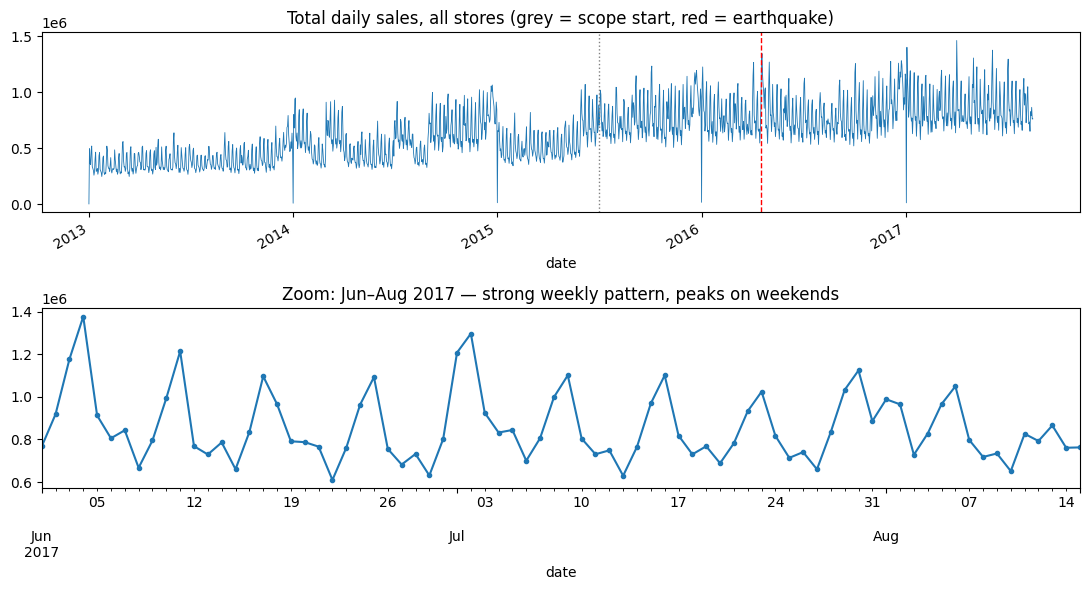

In [5]:
# Total sales over time; red line = 2016-04-16 earthquake
# Zaman içinde toplam satış; kırmızı çizgi = 16.04.2016 depremi
daily = train.groupby("date").sales.sum()
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
daily.plot(ax=ax[0], lw=0.6)
ax[0].axvline(pd.Timestamp("2016-04-16"), color="red", ls="--", lw=1)
ax[0].axvline(pd.Timestamp(data.SCOPE_START), color="grey", ls=":", lw=1)
ax[0].set_title("Total daily sales, all stores (grey = scope start, red = earthquake)")
daily["2017-06-01":].plot(ax=ax[1], marker=".")
ax[1].set_title("Zoom: Jun–Aug 2017 — strong weekly pattern, peaks on weekends")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "01_sales_over_time.png", dpi=110); plt.show()

In [6]:
# Chosen scope: all 54 stores x top-10 families, from 2015-07-01
# Seçilen kapsam: 54 mağaza x ilk 10 aile, 2015-07-01'den itibaren
df = data.load_scope()
n_series = df.groupby(["store_nbr", "family"], observed=True).ngroups
print("rows:", len(df), "| series:", n_series, "| dates:", df.date.min().date(), "->", df.date.max().date())
print("families:", list(df.family.cat.categories))
print("share of total sales covered:", round(df.sales.sum() / train.loc[train.date >= data.SCOPE_START, "sales"].sum(), 3))
print("zero-sales share in scope:", round((df.sales == 0).mean(), 3))

rows: 411250 | series: 540 | dates: 2015-07-01 -> 2017-08-15
families: ['BEVERAGES', 'BREAD/BAKERY', 'CLEANING', 'DAIRY', 'DELI', 'GROCERY I', 'MEATS', 'PERSONAL CARE', 'POULTRY', 'PRODUCE']
share of total sales covered: 0.93
zero-sales share in scope: 0.01


## Step 2 — Baselines / Adım 2 — Baseline modeller
**EN:** Two simple forecasts that any model must beat:
- **Naive:** every future day = the last known day.
- **Seasonal naive:** every future day = the same weekday in the last known week.

We test them on 4 rolling 16-day windows (the same windows used for LightGBM later). Each forecast only sees data up to its cutoff.

**TR:** Her modelin geçmesi gereken iki basit tahmin:
- **Naive:** gelecekteki her gün = bilinen son gün.
- **Seasonal naive:** gelecekteki her gün = bilinen son haftada aynı haftanın günü.

Bunları 4 adet kayan 16 günlük pencerede test ediyoruz (sonra LightGBM için de aynı pencereler). Her tahmin sadece kendi cutoff tarihine kadarki veriyi görür.

In [7]:
from src import baselines, evaluate

# Backtest windows: cutoff = last day the model may see
# Backtest pencereleri: cutoff = modelin görebileceği son gün
folds = evaluate.make_folds()
folds

,fold,cutoff,test_start,test_end
0,1,2017-06-12,2017-06-13,2017-06-28
1,2,2017-06-28,2017-06-29,2017-07-14
2,3,2017-07-14,2017-07-15,2017-07-30
3,4,2017-07-30,2017-07-31,2017-08-15


In [8]:
# Run both baselines on every fold and score them
# Her iki baseline'ı her fold'da çalıştır ve puanla
KEYS = ["date", "store_nbr", "family"]
base_preds, rows = [], []
for f in folds.itertuples():
    actual = df[(df.date >= f.test_start) & (df.date <= f.test_end)][KEYS + ["sales"]]
    for name, fn in {"naive": baselines.naive, "seasonal_naive": baselines.seasonal_naive}.items():
        pred = fn(df[df.date <= f.cutoff], f.cutoff, evaluate.HORIZON)
        m = actual.merge(pred, on=KEYS, how="left").assign(fold=f.fold, model=name)
        base_preds.append(m)
        rows.append({"fold": f.fold, "model": name, **evaluate.metrics(m.sales, m.pred)})
base_preds = pd.concat(base_preds, ignore_index=True)
base_scores = pd.DataFrame(rows)
base_scores.pivot(index="fold", columns="model", values=["MAE", "RMSE", "WAPE"]).round(3)

MAE                     RMSE                  WAPE               
model    naive seasonal_naive     naive seasonal_naive  naive seasonal_naive
fold                                                                        
1      316.016        227.921   716.284        532.965  0.225          0.162
2      444.873        232.726  1039.506        579.011  0.298          0.156
3      383.811        195.402   857.639        482.172  0.259          0.132
4      627.933        282.462  1313.135        628.457  0.438          0.197

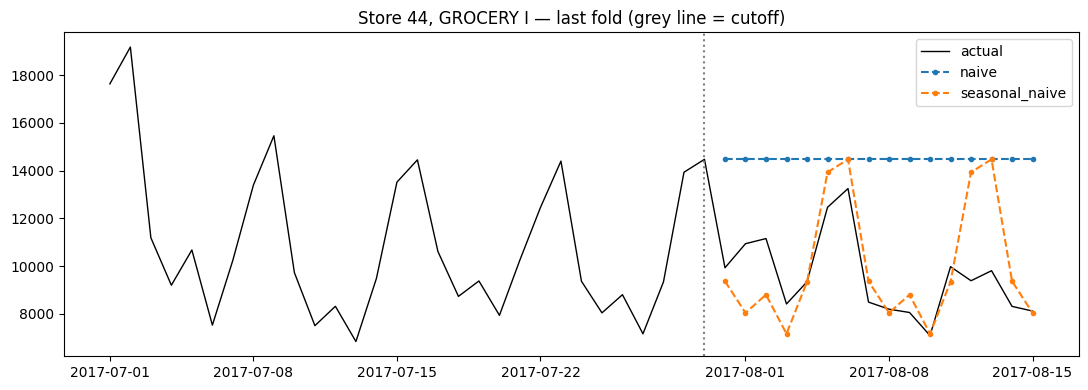

In [9]:
# Example series in the last fold: actual vs. baselines
# Son fold'da örnek bir seri: gerçek satış ve baseline'lar
ex = base_preds[(base_preds.fold == 4) & (base_preds.store_nbr == 44) & (base_preds.family == "GROCERY I")]
hist = df[(df.store_nbr == 44) & (df.family == "GROCERY I") & (df.date >= "2017-07-01")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.date, hist.sales, color="black", lw=1, label="actual")
for name, g in ex.groupby("model"):
    ax.plot(g.date, g.pred, ls="--", marker=".", label=name)
ax.axvline(folds.cutoff.iloc[-1], color="grey", ls=":")
ax.set_title("Store 44, GROCERY I — last fold (grey line = cutoff)"); ax.legend()
plt.tight_layout(); plt.savefig(data.FIG_DIR / "02_baselines_example.png", dpi=110); plt.show()

## Step 3 — LightGBM with features / Adım 3 — Özelliklerle LightGBM
**EN:** One global LightGBM model for all 540 series, trained on `log1p(sales)`.
- **Lags 7/14/28, rolling means 7/28, same-weekday mean of last 4 weeks.**
- **Calendar, payday** (15th and last day of month), **promotions** (known in advance).
- **Holidays:** a transferred holiday counts on its *Transfer* date, not the original date. Bridge and Work Day get their own flags. Regional and local holidays only apply to stores in that state or city.
- **Oil price:** 28-day mean, shifted 16 days, because future oil prices are unknown when we forecast.
- **Earthquake (2016-04-16 → 05-16):** these weeks are removed from training.

**No leakage:** for 16 days ahead, `lag_7` would look into the future. So we forecast **recursively**: predict day 1, use it as history, predict day 2, and so on.

**TR:** 540 serinin hepsi için tek bir global LightGBM modeli, hedef `log1p(satış)`.
- **Lag 7/14/28, rolling ortalama 7/28, son 4 haftada aynı günün ortalaması.**
- **Takvim, maaş günü** (ayın 15'i ve son günü), **promosyon** (önceden bilinir).
- **Tatiller:** taşınan tatil, orijinal tarihte değil *Transfer* tarihinde sayılır. Bridge ve Work Day ayrı bayraklar. Bölgesel ve yerel tatiller sadece o eyalet veya şehirdeki mağazalara uygulanır.
- **Petrol fiyatı:** 28 günlük ortalama, 16 gün kaydırılmış, çünkü tahmin anında gelecek fiyat bilinmez.
- **Deprem (16.04 → 16.05.2016):** bu haftalar eğitimden çıkarıldı.

**Sızıntı yok:** 16 gün ileriyi tahmin ederken `lag_7` geleceğe bakar. Bu yüzden **recursive** tahmin yapıyoruz: 1. günü tahmin et, geçmiş gibi kullan, 2. günü tahmin et, ve böyle devam et.

In [10]:
from src import features, model

# Build all features once (lags are rebuilt inside the recursive forecast)
# Tüm özellikleri bir kez kur (lag'ler recursive tahmin içinde yeniden kurulur)
feat = features.add_lag_features(features.add_exogenous(df))
print(feat.shape, "| features used:", len(features.FEATURES))
print(features.FEATURES)

(411250, 28) | features used: 24
['store_nbr', 'family', 'store_type', 'cluster', 'lag_7', 'lag_14', 'lag_28', 'rmean_7', 'rmean_28', 'dow_mean_4w', 'dayofweek', 'day', 'month', 'dayofyear', 'is_payday', 'days_since_payday', 'onpromotion', 'promo_share_family', 'hol_national', 'hol_local', 'is_bridge', 'is_workday', 'is_event', 'oil_ma28']


In [11]:
# Sanity check: 2017-08-10 holiday was moved to 08-11 (Transfer), payday on 08-15
# Kontrol: 10.08.2017 tatili 11.08'e taşındı (Transfer), maaş günü 15.08
cols = ["date", "hol_national", "is_bridge", "is_workday", "is_payday", "days_since_payday", "oil_ma28"]
feat[(feat.store_nbr == 1) & (feat.family == "GROCERY I") & feat.date.between("2017-08-09", "2017-08-15")][cols]

,date,hol_national,is_bridge,is_workday,is_payday,days_since_payday,oil_ma28
4655,2017-08-09,0,0,0,0,9,45.633571
4656,2017-08-10,0,0,0,0,10,45.759286
4657,2017-08-11,1,0,0,0,11,45.896429
4658,2017-08-12,0,0,0,0,12,46.045357
4659,2017-08-13,0,0,0,0,13,46.177500
4660,2017-08-14,0,0,0,0,14,46.309643
4661,2017-08-15,0,0,0,1,0,46.441786


In [12]:
# Training rows removed: closed days and the earthquake weeks
# Eğitimden çıkarılan satırlar: kapalı günler ve deprem haftaları
print("earthquake rows excluded:", int(feat.quake_period.sum()), "| closed-day rows excluded:", int(feat.is_closed.sum()))

# Train on data up to the last fold's cutoff and forecast 16 days
# Son fold'un cutoff tarihine kadar eğit ve 16 gün tahmin et
last = folds.iloc[-1]
lgb_model = model.train(feat, last.cutoff)
lgb_pred = model.forecast_recursive(lgb_model, feat, last.cutoff, evaluate.HORIZON)

actual = df[(df.date >= last.test_start) & (df.date <= last.test_end)][KEYS + ["sales"]]
m = actual.merge(lgb_pred, on=KEYS)
scores = base_scores[base_scores.fold == last.fold].set_index("model")[["MAE", "RMSE", "WAPE"]]
scores.loc["lightgbm"] = evaluate.metrics(m.sales, m.pred)
scores.round(3)

earthquake rows excluded: 16430 | closed-day rows excluded: 1060


,MAE,RMSE,WAPE
model,,,
naive,627.933,1313.135,0.438
seasonal_naive,282.462,628.457,0.197
lightgbm,192.544,411.356,0.134


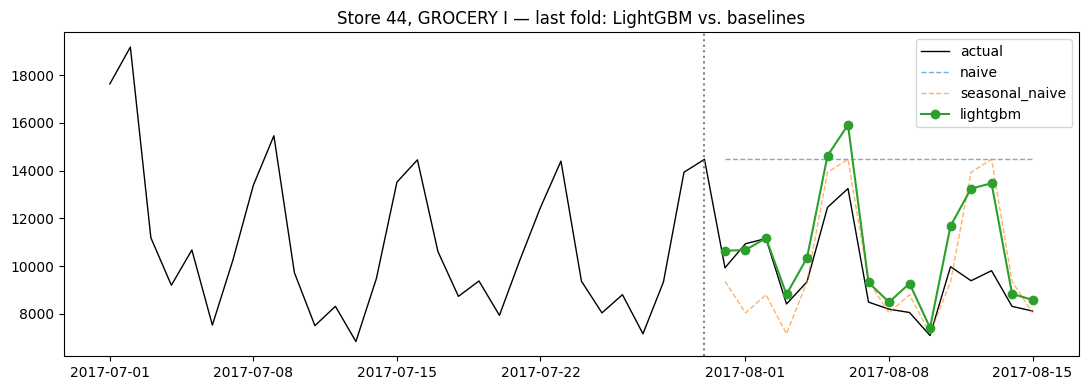

In [13]:
# Same example series as in Step 2, now with LightGBM
# Adım 2'deki aynı örnek seri, şimdi LightGBM ile
ex_l = lgb_pred[(lgb_pred.store_nbr == 44) & (lgb_pred.family == "GROCERY I")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.date, hist.sales, color="black", lw=1, label="actual")
for name, g in ex.groupby("model"):
    ax.plot(g.date, g.pred, ls="--", lw=1, alpha=0.6, label=name)
ax.plot(ex_l.date, ex_l.pred, marker="o", color="tab:green", label="lightgbm")
ax.axvline(last.cutoff, color="grey", ls=":")
ax.set_title("Store 44, GROCERY I — last fold: LightGBM vs. baselines"); ax.legend()
plt.tight_layout(); plt.savefig(data.FIG_DIR / "03_lightgbm_example.png", dpi=110); plt.show()

## Step 4 — Rolling-window backtest / Adım 4 — Kayan pencereli backtest
**EN:** For each of the 4 folds we retrain LightGBM using only data up to the cutoff, then forecast the next 16 days. The baselines use the same windows. One good fold could be luck; 4 folds show whether the gain is stable.

**TR:** 4 fold'un her birinde LightGBM'i sadece cutoff'a kadarki veriyle yeniden eğitip sonraki 16 günü tahmin ediyoruz. Baseline'lar da aynı pencereleri kullanıyor. Tek bir iyi fold şans olabilir; 4 fold kazancın istikrarlı olup olmadığını gösterir.

In [14]:
from src import backtest

# Retrain + forecast per fold (about 15 s per fold on a laptop CPU)
# Her fold için yeniden eğit + tahmin et (laptop CPU'sunda fold başına ~15 sn)
res = backtest.run_backtest(df, feat, folds)
res.to_parquet(ROOT / "reports" / "backtest_preds.parquet")  # used in Step 6 / Adım 6'da kullanılır

fold 1 done in 22.6s


fold 2 done in 21.6s


fold 3 done in 22.0s


fold 4 done in 23.2s


In [15]:
# Main results table: WAPE / MAE / RMSE per fold and model
# Ana sonuç tablosu: fold ve model başına WAPE / MAE / RMSE
sc = backtest.score(res)
table = sc.pivot(index="fold", columns="model", values=["WAPE", "MAE", "RMSE"])
table.loc["mean"] = table.mean()
order = ["naive", "seasonal_naive", "lightgbm"]
table = table.reindex(columns=pd.MultiIndex.from_product([["WAPE", "MAE", "RMSE"], order]))
table.round(3).to_csv(ROOT / "reports" / "backtest_metrics.csv")
gain = 1 - table[("WAPE", "lightgbm")] / table[("WAPE", "seasonal_naive")]
print("LightGBM WAPE improvement vs seasonal naive per fold:", (gain * 100).round(1).to_dict())
table.round(3)

LightGBM WAPE improvement vs seasonal naive per fold: {1: 30.5, 2: 38.4, 3: 13.5, 4: 31.8, 'mean': 29.3}


WAPE                              MAE                              RMSE                        
      naive seasonal_naive lightgbm    naive seasonal_naive lightgbm     naive seasonal_naive lightgbm
fold                                                                                                  
1     0.225          0.162    0.113  316.016        227.921  158.340   716.284        532.965  396.092
2     0.298          0.156    0.096  444.873        232.726  143.461  1039.506        579.011  359.579
3     0.259          0.132    0.114  383.811        195.402  168.937   857.639        482.172  384.667
4     0.438          0.197    0.134  627.933        282.462  192.544  1313.135        628.457  411.356
mean  0.305          0.162    0.114  443.158        234.628  165.820   981.641        555.651  387.924

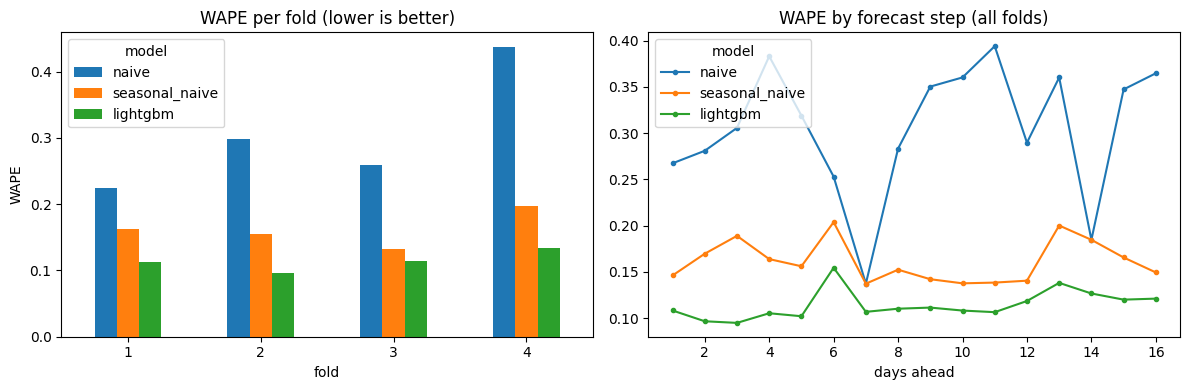

In [16]:
# WAPE per fold (left) and by forecast step 1..16 (right)
# Fold başına WAPE (sol) ve tahmin adımına göre 1..16 (sağ)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sc.pivot(index="fold", columns="model", values="WAPE")[order].plot.bar(ax=ax[0], rot=0)
ax[0].set_title("WAPE per fold (lower is better)"); ax[0].set_ylabel("WAPE")
by_h = backtest.score(res, by=("h", "model")).pivot(index="h", columns="model", values="WAPE")[order]
by_h.plot(ax=ax[1], marker=".")
ax[1].set_title("WAPE by forecast step (all folds)"); ax[1].set_xlabel("days ahead")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "04_backtest_wape.png", dpi=110); plt.show()

In [17]:
# Where is LightGBM better or worse? WAPE by family (all folds)
# LightGBM nerede daha iyi veya kötü? Aileye göre WAPE (tüm fold'lar)
by_fam = backtest.score(res, by=("family", "model")).pivot(index="family", columns="model", values="WAPE")[order]
by_fam["gain_vs_snaive_%"] = (1 - by_fam.lightgbm / by_fam.seasonal_naive) * 100
by_fam.sort_values("gain_vs_snaive_%").round(3)

model,naive,seasonal_naive,lightgbm,gain_vs_snaive_%
family,,,,
PRODUCE,0.288,0.098,0.085,12.947
DAIRY,0.249,0.118,0.101,14.487
BREAD/BAKERY,0.243,0.125,0.107,14.519
MEATS,0.366,0.151,0.121,19.800
DELI,0.304,0.166,0.124,25.035
POULTRY,0.355,0.155,0.114,26.633
BEVERAGES,0.334,0.185,0.134,27.810
GROCERY I,0.264,0.147,0.095,35.379
PERSONAL CARE,0.377,0.237,0.146,38.422


## Step 5 — SHAP: what drives the forecast / Adım 5 — SHAP: tahmini ne yönlendiriyor
**EN:** SHAP splits each prediction into contributions from each feature. We use LightGBM's built-in exact TreeSHAP (it handles categorical features correctly) on 5,000 random rows from the last 90 days before the final cutoff. Values are in `log1p(sales)` space, so +0.10 ≈ +10% sales.

**TR:** SHAP her tahmini özelliklerin katkılarına ayırır. LightGBM'in yerleşik kesin TreeSHAP hesabını (kategorik özellikleri doğru işler) son cutoff'tan önceki 90 günden rastgele 5.000 satır üzerinde kullanıyoruz. Değerler `log1p(satış)` ölçeğinde, yani +0.10 ≈ +%10 satış.

In [18]:
import shap
from src import explain

# Explain the last-fold model on recent training rows
# Son fold modelini yakın tarihli eğitim satırları üzerinde açıkla
tr_rows = model.training_rows(feat, last.cutoff)
X_shap = tr_rows[tr_rows.date > last.cutoff - pd.Timedelta(days=90)].sample(5000, random_state=0)
exp = explain.shap_values(lgb_model, X_shap)

# Check: base value + SHAP values = model prediction
# Kontrol: başlangıç değeri + SHAP değerleri = model tahmini
import numpy as np
print("max additivity error:", np.abs(exp.values.sum(1) + exp.base_values - lgb_model.predict(X_shap[features.FEATURES])).max())

max additivity error: 3.730349362740526e-14


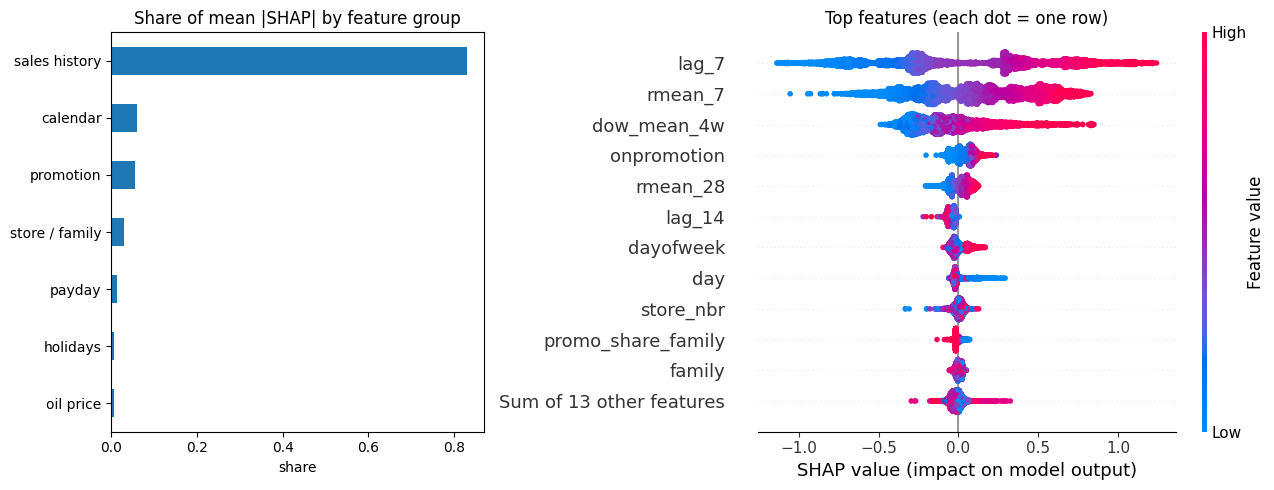

sales history     0.829
calendar          0.061
promotion         0.056
store / family    0.029
payday            0.013
holidays          0.006
oil price         0.006
dtype: float64

In [19]:
# Importance by feature group (share of mean |SHAP|)
# Özellik grubuna göre önem (ortalama |SHAP| payı)
grp = explain.group_importance(exp)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})
grp.sort_values().plot.barh(ax=ax[0], color="tab:blue")
ax[0].set_title("Share of mean |SHAP| by feature group"); ax[0].set_xlabel("share")
plt.sca(ax[1])
shap.plots.beeswarm(exp, max_display=12, show=False, plot_size=None)
ax[1].set_title("Top features (each dot = one row)")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "05_shap_summary.png", dpi=110, bbox_inches="tight"); plt.show()
grp.round(3)

In [20]:
# Rare features matter a lot when they are 'on': mean SHAP when the flag is set
# Nadir özellikler 'açık' olduklarında çok önemli: bayrak açıkken ortalama SHAP
rows = []
for col, cond in [("onpromotion", X_shap.onpromotion > 0), ("hol_national", X_shap.hol_national == 1),
                  ("hol_local", X_shap.hol_local == 1), ("is_payday", X_shap.is_payday == 1)]:
    i = features.FEATURES.index(col)
    rows.append({"feature": col, "rows_with_flag": int(cond.sum()),
                 "mean_shap_when_on": exp.values[cond.values, i].mean(),
                 "mean_shap_when_off": exp.values[~cond.values, i].mean()})
pd.DataFrame(rows).round(3)

,feature,rows_with_flag,mean_shap_when_on,mean_shap_when_off
0,onpromotion,4114,0.054,-0.054
1,hol_national,124,0.101,-0.004
2,hol_local,30,-0.013,0.000
3,is_payday,285,0.019,-0.001


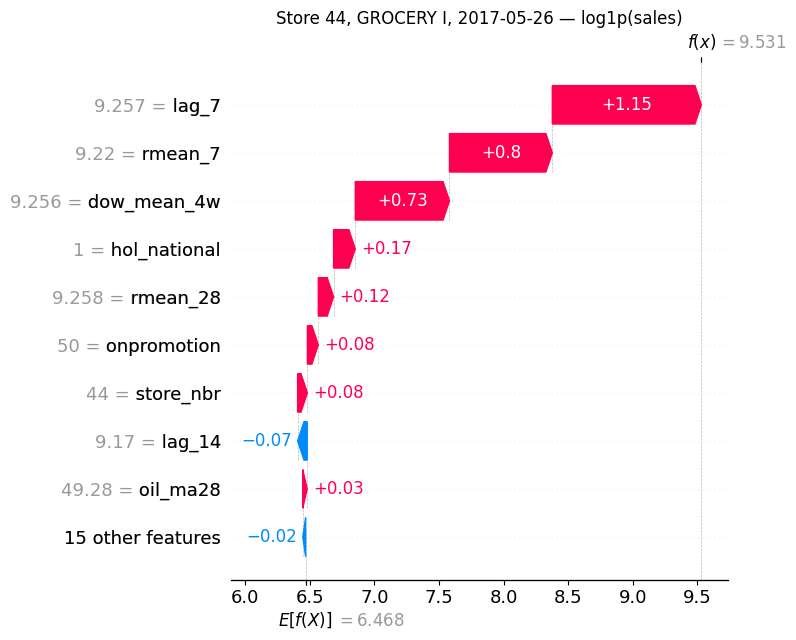

In [21]:
# One prediction explained: store 44, GROCERY I on 2017-05-26 (transferred national holiday)
# Tek tahminin açıklaması: mağaza 44, GROCERY I, 26.05.2017 (taşınan ulusal tatil)
one = feat[(feat.store_nbr == 44) & (feat.family == "GROCERY I") & (feat.date == "2017-05-26")]
e1 = explain.shap_values(lgb_model, one)
shap.plots.waterfall(e1[0], max_display=10, show=False)
plt.title("Store 44, GROCERY I, 2017-05-26 — log1p(sales)")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "05_shap_waterfall.png", dpi=110, bbox_inches="tight"); plt.show()

## Step 6 — Inventory simulation / Adım 6 — Stok simülasyonu
**EN:** ⚠️ **This is a simulation.** There is no real inventory data. We use recorded sales as demand, but sales are *censored demand*: on stockout days the true demand was higher than what was sold, and we cannot see it.

- **Policy:** daily review, order-up-to. Every evening: order = target − (stock on hand + stock on order). Target = forecast of the next 4 days + safety stock.
- **Lead time:** 3 days. An order placed on the evening of day *t* can be sold from day *t+4*, so each order covers 4 days.
- **Lost sales:** demand that cannot be served is lost.
- **Forecasts:** re-forecast every evening with data up to that day. LightGBM is retrained every 16 days at the fold cutoffs.
- **Safety stock:** z × σ. σ = RMSE of the 4-day forecast error, per series and method, measured in a calibration period *before* the simulation (2017-04-25 → 06-08). z = 1.645 for a 95% service level.
- **Metrics:** fill rate (share of demand served) and average end-of-day inventory.

**TR:** ⚠️ **Bu bir simülasyondur.** Gerçek stok verisi yok. Talep olarak kayıtlı satışları kullanıyoruz, ama satışlar *sansürlü talep*: stoksuz günlerde gerçek talep satılandan fazlaydı ve bunu göremiyoruz.

- **Politika:** günlük gözden geçirme, order-up-to. Her akşam: sipariş = hedef − (eldeki stok + yoldaki stok). Hedef = sonraki 4 günün tahmini + emniyet stoğu.
- **Tedarik süresi:** 3 gün. *t* günü akşamı verilen sipariş *t+4* gününden itibaren satılabilir, yani her sipariş 4 günü karşılar.
- **Kayıp satış:** karşılanamayan talep kaybolur.
- **Tahminler:** her akşam o güne kadarki veriyle yeniden tahmin. LightGBM fold cutoff'larında 16 günde bir yeniden eğitilir.
- **Emniyet stoğu:** z × σ. σ = 4 günlük tahmin hatasının RMSE'si, seri ve yöntem başına, simülasyondan *önceki* kalibrasyon döneminde (25.04 → 08.06.2017) ölçülür. %95 servis seviyesi için z = 1.645.
- **Metrikler:** fill rate (karşılanan talep payı) ve ortalama gün sonu stok.

In [22]:
from src import inventory as inv

# Simulation = the 64 backtest days; orders after 08-11 cannot arrive in time
# Simülasyon = 64 backtest günü; 11.08'den sonraki siparişler zamanında gelemez
sim_days = pd.date_range(folds.test_start.iloc[0], folds.test_end.iloc[-1])
first_cut = sim_days[0] - pd.Timedelta(days=1)
sim_cutoffs = pd.date_range(first_cut, sim_days[-1] - pd.Timedelta(days=inv.LEAD_TIME + 1))

# Calibration period before the simulation, also retrained every 16 days
# Simülasyondan önceki kalibrasyon dönemi, o da 16 günde bir yeniden eğitilir
cal_retrain = [first_cut - pd.Timedelta(days=16 * k) for k in (3, 2, 1)]
cal_cutoffs = pd.date_range(cal_retrain[0], first_cut - pd.Timedelta(days=inv.PROTECTION))
print("simulation:", sim_days[0].date(), "->", sim_days[-1].date(), f"({len(sim_days)} days)")
print("calibration cutoffs:", cal_cutoffs[0].date(), "->", cal_cutoffs[-1].date())

simulation: 2017-06-13 -> 2017-08-15 (64 days)
calibration cutoffs: 2017-04-25 -> 2017-06-08


In [23]:
# Daily 4-day forecasts for every method (takes ~3 minutes on a laptop CPU)
# Her yöntem için günlük 4 günlük tahminler (laptop CPU'sunda ~3 dakika)
fc_cal = inv.daily_forecasts(df, feat, cal_cutoffs, cal_retrain)
fc_sim = inv.daily_forecasts(df, feat, sim_cutoffs, folds.cutoff)
sigma = inv.error_sigma(fc_cal, inv.protection_actuals(df, cal_cutoffs))

# How good are the 4-day forecasts inside the simulation?
# Simülasyon içinde 4 günlük tahminler ne kadar iyi?
chk = fc_sim.merge(inv.protection_actuals(df, sim_cutoffs), on=["cutoff", "store_nbr", "family"])
chk.groupby("method").apply(lambda g: pd.Series({
    "WAPE_4day": (g.fc_sum - g.actual_sum).abs().sum() / g.actual_sum.sum(),
    "bias_%": 100 * (g.fc_sum.sum() / g.actual_sum.sum() - 1),
    "sum_sigma": sigma.loc[sigma.method == g.name, "sigma"].sum()}), include_groups=False).round(3)

45 daily cutoffs in 85s


61 daily cutoffs in 117s


,WAPE_4day,bias_%,sum_sigma
method,,,
lightgbm,0.071,0.825,359067.770
naive,0.255,-0.222,1167784.758
seasonal_naive,0.122,1.235,552202.077


In [24]:
# Main result (95%) and what-if (90% / 99%)
# Ana sonuç (%95) ve senaryo (%90 / %99)
sim = pd.concat([inv.run(df, fc_sim, sigma, sim_days, sl) for sl in (0.90, 0.95, 0.99)], ignore_index=True)
sim.to_csv(ROOT / "reports" / "inventory_simulation.csv", index=False)
view = sim.set_index(["service_level", "method"])[["fill_rate", "avg_inventory", "days_of_cover", "stockout_days_%"]]
view.style.format({"fill_rate": "{:.2%}", "avg_inventory": "{:,.0f}", "days_of_cover": "{:.2f}", "stockout_days_%": "{:.1f}"})

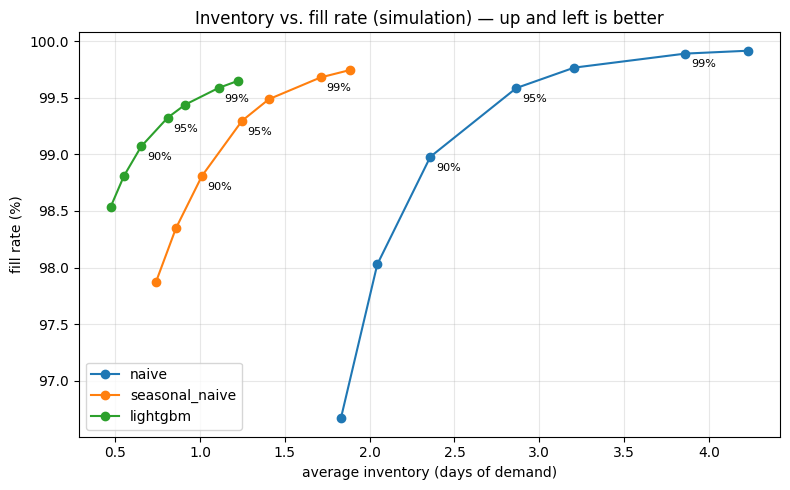

days of inventory needed for 99.5% fill rate: {'naive': 2.79, 'seasonal_naive': 1.43, 'lightgbm': 0.99}


In [25]:
# Fair comparison: trade-off curve (fill rate vs. inventory) over many service levels
# Adil karşılaştırma: birçok servis seviyesinde ödünleşim eğrisi (fill rate ve stok)
levels = [0.80, 0.85, 0.90, 0.95, 0.97, 0.99, 0.995]
curve = pd.concat([inv.run(df, fc_sim, sigma, sim_days, sl) for sl in levels], ignore_index=True)
order = ["naive", "seasonal_naive", "lightgbm"]
fig, ax = plt.subplots(figsize=(8, 5))
for mth in order:
    g = curve[curve.method == mth]
    ax.plot(g.days_of_cover, 100 * g.fill_rate, marker="o", label=mth)
    for sl in (0.90, 0.95, 0.99):
        r = g[g.service_level == sl].iloc[0]
        ax.annotate(f"{sl:.0%}", (r.days_of_cover, 100 * r.fill_rate), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.set_xlabel("average inventory (days of demand)"); ax.set_ylabel("fill rate (%)")
ax.set_title("Inventory vs. fill rate (simulation) — up and left is better"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(data.FIG_DIR / "06_inventory_tradeoff.png", dpi=110); plt.show()

# Inventory needed to reach the same fill rate (interpolated on the curve)
# Aynı fill rate'e ulaşmak için gereken stok (eğri üzerinde ara değer)
target_fr = 0.995
need = {mth: np.interp(target_fr, curve[curve.method == mth].fill_rate, curve[curve.method == mth].days_of_cover) for mth in order}
print(f"days of inventory needed for {target_fr:.1%} fill rate:", {k: round(v, 2) for k, v in need.items()})

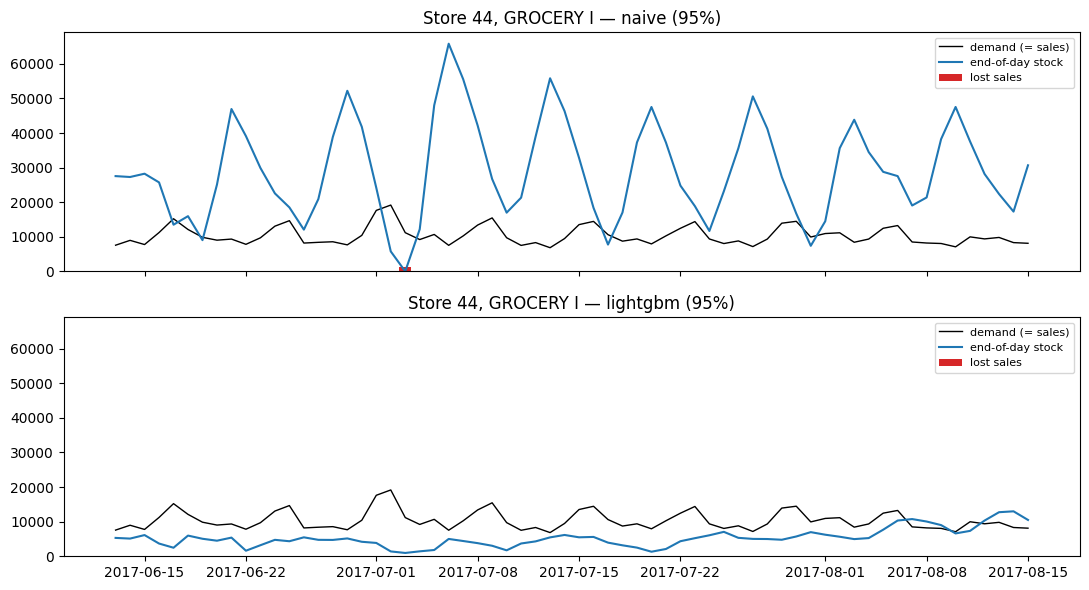

In [26]:
# One series over time: stock and lost sales, naive vs. LightGBM (95%)
# Tek seri zaman içinde: stok ve kayıp satış, naive ve LightGBM (%95)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for a, mth in zip(ax, ["naive", "lightgbm"]):
    dem, sold, stock = inv.simulate_method(df, fc_sim, sigma, sim_days, mth, 0.95)
    i = dem.index.get_loc((44, "GROCERY I"))
    a.plot(sim_days, dem.iloc[i].values, color="black", lw=1, label="demand (= sales)")
    a.plot(sim_days, stock[i], color="tab:blue", label="end-of-day stock")
    lost = dem.iloc[i].values - sold[i]
    a.bar(sim_days, lost, color="tab:red", label="lost sales")
    a.set_title(f"Store 44, GROCERY I — {mth} (95%)"); a.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(data.FIG_DIR / "06_inventory_example.png", dpi=110); plt.show()